# ASSIGNMENT 6 — Recurrent Neural Network (RNN)
**Họ và tên:** Trần Đình Hiếu  **MSV:** B23DCCE034

## Notebook 01 — RNN *from scratch* (NumPy) cho 2 bộ dữ liệu

Toàn bộ mạng được tự cài đặt chỉ bằng NumPy: lan truyền thuận, lan truyền ngược theo thời gian (BPTT), tối ưu **Adam**, **gradient clipping**, mini-batch và early stopping. Không dùng framework deep learning nào.

Kiến trúc (many-to-one): `x_1..x_T → RNN(tanh, H=64) → h_T → Dense(1) → ŷ`

In [1]:
import os, json, time, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
SEED = 42
np.random.seed(SEED)

## Dữ liệu & tiền xử lý (dùng chung cho cả 3 thư viện)

| Bộ dữ liệu | Nguồn | Chuỗi thời gian dự báo | Cửa sổ (window) |
|---|---|---|---|
| **E-commerce service process** | `olist_orders_dataset.csv` (Olist, Brazil) | Số đơn hàng được đặt mỗi ngày (15/01/2017 → 22/08/2018) | 14 ngày |
| **Stock** | `indexProcessed.csv` | Giá đóng cửa (USD) chỉ số NASDAQ – `IXIC` (2010 → 05/2021) | 30 phiên |

Các bước:
1. Gom chuỗi theo ngày (đơn hàng) / lọc chỉ số (cổ phiếu).
2. Chia **theo thời gian**: 80% đầu là train, 20% cuối là test (không xáo trộn để tránh rò rỉ thông tin tương lai).
3. Chuẩn hóa — chỉ dùng thống kê của tập train:
   * E-commerce: **Min-Max** về [0, 1].
   * Stock: **chuẩn hóa tương đối** $x'_k = (x_k / x_{t-1} - 1)/s$ (chia cho giá phiên cuối của cửa sổ, $s$ = độ lệch chuẩn lợi suất ngày trên train). Giá NASDAQ giai đoạn test cao hơn hẳn train nên Min-Max sẽ buộc mạng phải *ngoại suy* ngoài [0,1]; cách chuẩn hóa tương đối biến chuỗi thành dừng.
4. Tạo mẫu bằng **cửa sổ trượt**: $X = [x_{t-w}, \dots, x_{t-1}]$ → $y = x_t$ (bài toán *many-to-one*).
5. Đánh giá trên thang giá trị gốc bằng RMSE, MAE, MAPE, $R^2$ và so sánh với **baseline naive** ($\hat{x}_t = x_{t-1}$).

In [2]:
DATA_DIR = '.'          # thư mục chứa 2 file CSV
os.makedirs('figures', exist_ok=True)
os.makedirs('results', exist_ok=True)

def load_ecommerce():
    o = pd.read_csv(f'{DATA_DIR}/olist_orders_dataset.csv', parse_dates=['order_purchase_timestamp'])
    s = o.set_index('order_purchase_timestamp').resample('D').size().astype(float)
    s = s['2017-01-15':'2018-08-22']
    s.name = 'orders_per_day'
    return s

def load_stock(index='IXIC', start='2010-01-01'):
    d = pd.read_csv(f'{DATA_DIR}/indexProcessed.csv', parse_dates=['Date'])
    d = d[d['Index'] == index].set_index('Date').sort_index()
    s = d.loc[start:, 'CloseUSD'].astype(float)
    s.name = f'{index}_close_usd'
    return s

class MinMaxScaler1D:
    def fit(self, x):
        self.min, self.max = float(np.min(x)), float(np.max(x))
        return self
    def transform(self, x):
        return (np.asarray(x) - self.min) / (self.max - self.min)
    def inverse_transform(self, x):
        return np.asarray(x) * (self.max - self.min) + self.min

def prepare(series, window, scaling='minmax', train_ratio=0.8):
    # scaling='minmax'  : x' = (x - min) / (max - min), fit trên train.
    # scaling='relative': x' = (x / x_{t-1} - 1) / s  — chuẩn hóa theo giá cuối cửa sổ (s = độ lệch chuẩn lợi suất train),
    #                     giúp chuỗi không dừng (giá cổ phiếu) trở nên dừng và không phải ngoại suy.
    values = series.values.astype(np.float64)
    n_train = int(len(values) * train_ratio)
    target_idx = np.arange(window, len(values))
    base = values[target_idx - 1]                                   # giá trị ngay trước mục tiêu
    windows = np.stack([values[i - window:i] for i in target_idx])  # (N, T)
    targets = values[target_idx]
    is_train = target_idx < n_train
    if scaling == 'minmax':
        scaler = MinMaxScaler1D().fit(values[:n_train])
        X, y = scaler.transform(windows), scaler.transform(targets)
        inverse = lambda y_s, b: scaler.inverse_transform(y_s)
    else:
        s = float(np.std(targets[is_train] / base[is_train] - 1))
        X, y = (windows / base[:, None] - 1) / s, (targets / base - 1) / s
        inverse = lambda y_s, b: (np.asarray(y_s) * s + 1) * b
    test_base = base[~is_train]
    return dict(name=series.name, series=series, window=window, scaling=scaling,
                X_train=X[is_train][..., None], y_train=y[is_train][:, None],     # (N, T, 1), (N, 1)
                X_test=X[~is_train][..., None], y_test=y[~is_train][:, None],
                dates_test=series.index[target_idx[~is_train]],
                y_test_orig=targets[~is_train],
                naive_test=test_base,                                   # baseline: giá trị hôm trước
                to_original=lambda y_s: inverse(np.ravel(y_s), test_base))

def regression_metrics(y_true, y_pred):
    y_true, y_pred = np.ravel(y_true), np.ravel(y_pred)
    err = y_pred - y_true
    mask = y_true != 0
    return dict(RMSE=float(np.sqrt(np.mean(err ** 2))),
                MAE=float(np.mean(np.abs(err))),
                MAPE=float(np.mean(np.abs(err[mask] / y_true[mask])) * 100),
                R2=float(1 - np.sum(err ** 2) / np.sum((y_true - y_true.mean()) ** 2)))

DATASETS = {
    'ecommerce': prepare(load_ecommerce(), window=14, scaling='minmax'),
    'stock':     prepare(load_stock('IXIC'), window=30, scaling='relative'),
}
for k, d in DATASETS.items():
    print(f"{k:10s} | series={len(d['series'])} | X_train={d['X_train'].shape} | X_test={d['X_test'].shape}")

ecommerce  | series=585 | X_train=(454, 14, 1) | X_test=(117, 14, 1)
stock      | series=2871 | X_train=(2266, 30, 1) | X_test=(575, 30, 1)


## 1. Cài đặt lớp RNN

* **Khởi tạo:** $W_{xh}$ theo Xavier/Glorot, $W_{hh}$ **trực giao** (giữ chuẩn gradient ≈ 1, giảm vanishing/exploding), bias = 0.
* **forward(X):** X có dạng `(B, T, D)`; lưu lại mọi $h_t$ để dùng cho BPTT.
* **backward(dy):** BPTT đầy đủ, cộng dồn gradient qua các bước thời gian.

In [3]:
class RNNScratch:
    def __init__(self, input_dim, hidden_dim, output_dim, seed=SEED):
        rng = np.random.default_rng(seed)
        D, H, O = input_dim, hidden_dim, output_dim
        lim = np.sqrt(6 / (D + H))
        self.params = {
            'W_xh': rng.uniform(-lim, lim, (H, D)),
            'W_hh': np.linalg.qr(rng.standard_normal((H, H)))[0],   # khởi tạo trực giao
            'b_h':  np.zeros(H),
            'W_hy': rng.uniform(-np.sqrt(6 / (H + O)), np.sqrt(6 / (H + O)), (O, H)),
            'b_y':  np.zeros(O),
        }

    def forward(self, X):
        # X: (B, T, D)  ->  y_hat: (B, O)
        p = self.params
        B, T, _ = X.shape
        H = p['W_hh'].shape[0]
        self.X = X
        self.hs = [np.zeros((B, H))]                                   # h_0 = 0
        for t in range(T):
            a_t = X[:, t, :] @ p['W_xh'].T + self.hs[-1] @ p['W_hh'].T + p['b_h']
            self.hs.append(np.tanh(a_t))
        return self.hs[-1] @ p['W_hy'].T + p['b_y']

    def backward(self, dy):
        # dy = dL/dy_hat : (B, O). Trả về dict gradient cùng tên với params.
        p, X, hs = self.params, self.X, self.hs
        T = X.shape[1]
        g = {k: np.zeros_like(v) for k, v in p.items()}
        g['W_hy'] = dy.T @ hs[-1]
        g['b_y'] = dy.sum(0)
        dh = dy @ p['W_hy']                                            # dL/dh_T
        for t in reversed(range(T)):
            da = dh * (1 - hs[t + 1] ** 2)                             # qua tanh  (Hadamard)
            g['W_xh'] += da.T @ X[:, t, :]                             # outer product cộng dồn
            g['W_hh'] += da.T @ hs[t]
            g['b_h'] += da.sum(0)
            dh = da @ p['W_hh']                                        # truyền về h_{t-1}  (W_hh^T δ)
        return g

    def predict(self, X, batch_size=512):
        return np.vstack([self.forward(X[i:i + batch_size]) for i in range(0, len(X), batch_size)])

    def n_params(self):
        return sum(v.size for v in self.params.values())


def mse_loss(y_hat, y):
    diff = y_hat - y
    return float(np.mean(diff ** 2)), 2 * diff / diff.size            # (loss, dL/dy_hat)


class Adam:
    def __init__(self, params, lr=1e-3, beta1=0.9, beta2=0.999, eps=1e-8):
        self.lr, self.b1, self.b2, self.eps, self.t = lr, beta1, beta2, eps, 0
        self.m = {k: np.zeros_like(v) for k, v in params.items()}
        self.v = {k: np.zeros_like(v) for k, v in params.items()}

    def step(self, params, grads):
        self.t += 1
        for k in params:
            self.m[k] = self.b1 * self.m[k] + (1 - self.b1) * grads[k]
            self.v[k] = self.b2 * self.v[k] + (1 - self.b2) * grads[k] ** 2
            m_hat = self.m[k] / (1 - self.b1 ** self.t)
            v_hat = self.v[k] / (1 - self.b2 ** self.t)
            params[k] -= self.lr * m_hat / (np.sqrt(v_hat) + self.eps)


def clip_by_global_norm(grads, max_norm):
    total = np.sqrt(sum(np.sum(g ** 2) for g in grads.values()))
    scale = min(1.0, max_norm / (total + 1e-12))
    return {k: g * scale for k, g in grads.items()}, total

## 2. Kiểm tra gradient bằng sai phân hữu hạn (gradient check)

So sánh gradient giải tích (BPTT) với gradient số $\frac{L(\theta+\epsilon)-L(\theta-\epsilon)}{2\epsilon}$. Sai số tương đối ~$10^{-7}$ trở xuống chứng tỏ BPTT cài đặt đúng.

In [4]:
rng = np.random.default_rng(0)
m = RNNScratch(input_dim=2, hidden_dim=5, output_dim=1, seed=1)
Xc, yc = rng.standard_normal((4, 6, 2)), rng.standard_normal((4, 1))
loss, dy = mse_loss(m.forward(Xc), yc)
grads = m.backward(dy)
eps = 1e-6
for name, P in m.params.items():
    num = np.zeros_like(P)
    it = np.nditer(P, flags=['multi_index'])
    for _ in it:
        i = it.multi_index; old = P[i]
        P[i] = old + eps; lp, _ = mse_loss(m.forward(Xc), yc)
        P[i] = old - eps; lm, _ = mse_loss(m.forward(Xc), yc)
        P[i] = old; num[i] = (lp - lm) / (2 * eps)
    rel = np.linalg.norm(num - grads[name]) / (np.linalg.norm(num) + np.linalg.norm(grads[name]) + 1e-12)
    print(f'{name:5s} sai số tương đối = {rel:.2e}')

W_xh  sai số tương đối = 1.27e-10
W_hh  sai số tương đối = 2.63e-10
b_h   sai số tương đối = 1.28e-10
W_hy  sai số tương đối = 7.86e-11
b_y   sai số tương đối = 1.80e-11


## 3. Vòng lặp huấn luyện

* 10% cuối của tập train (theo thời gian) làm **validation**; giữ lại tham số có val loss nhỏ nhất (**early stopping**, patience = 15).
* Mini-batch 32, xáo trộn các cửa sổ trong train (mỗi cửa sổ là một mẫu độc lập), Adam lr = 1e-3, clip norm = 1.0.

In [5]:
HIDDEN, LR, BATCH, EPOCHS, PATIENCE, CLIP = 64, 1e-3, 32, 150, 15, 1.0

def train_scratch(d, hidden=HIDDEN, lr=LR, batch=BATCH, epochs=EPOCHS, patience=PATIENCE, clip=CLIP, verbose=10):
    X, y = d['X_train'], d['y_train']
    n_val = int(len(X) * 0.1)
    X_tr, y_tr, X_val, y_val = X[:-n_val], y[:-n_val], X[-n_val:], y[-n_val:]
    model = RNNScratch(X.shape[2], hidden, 1)
    opt = Adam(model.params, lr)
    rng = np.random.default_rng(SEED)
    hist = {'train': [], 'val': [], 'grad_norm': []}
    best, best_params, wait = np.inf, None, 0
    for ep in range(1, epochs + 1):
        idx = rng.permutation(len(X_tr))
        losses, norms = [], []
        for i in range(0, len(idx), batch):
            b = idx[i:i + batch]
            loss, dy = mse_loss(model.forward(X_tr[b]), y_tr[b])
            grads, gnorm = clip_by_global_norm(model.backward(dy), clip)
            opt.step(model.params, grads)
            losses.append(loss * len(b)); norms.append(gnorm)
        val_loss, _ = mse_loss(model.predict(X_val), y_val)
        hist['train'].append(sum(losses) / len(X_tr)); hist['val'].append(val_loss); hist['grad_norm'].append(np.mean(norms))
        if val_loss < best:
            best, best_params, wait = val_loss, copy.deepcopy(model.params), 0
        else:
            wait += 1
        if verbose and (ep % verbose == 0 or ep == 1):
            print(f'epoch {ep:3d} | train {hist["train"][-1]:.5f} | val {val_loss:.5f} | ||g|| {np.mean(norms):.3f}')
        if wait >= patience:
            print(f'Early stopping tại epoch {ep}, best val = {best:.5f}')
            break
    model.params = best_params
    return model, hist

In [6]:
def plot_results(key, history, y_true, y_pred, lib, train_label='train', val_label='val'):
    d = DATASETS[key]
    fig, axes = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={'width_ratios': [1, 2.3]})
    axes[0].plot(history['train'], label=train_label)
    if history.get('val'):
        axes[0].plot(history['val'], label=val_label)
    axes[0].set_title('Loss (MSE, dữ liệu đã chuẩn hóa)'); axes[0].set_xlabel('epoch'); axes[0].legend()
    axes[1].plot(d['dates_test'], y_true, label='Thực tế', color='black', lw=1.2)
    axes[1].plot(d['dates_test'], y_pred, label=f'Dự báo RNN ({lib})', color='tab:red', lw=1.2, alpha=.85)
    axes[1].set_title(f'{key}: dự báo 1 bước trên tập test'); axes[1].legend()
    plt.tight_layout()
    plt.savefig(f'figures/{lib}_{key}.png', dpi=110)
    plt.show()

def save_results(lib, key, metrics, naive, train_time, epochs, extra=None):
    out = dict(library=lib, dataset=key, metrics=metrics, naive_baseline=naive,
               train_time_sec=round(train_time, 2), epochs=epochs, **(extra or {}))
    with open(f'results/{lib}_{key}.json', 'w', encoding='utf-8') as f:
        json.dump(out, f, indent=2, ensure_ascii=False)
    return out

## 4. Dataset: E-commerce — số đơn hàng mỗi ngày (Olist)

epoch   1 | train 0.00576 | val 0.00113 | ||g|| 0.285


epoch  10 | train 0.00234 | val 0.00100 | ||g|| 0.037


epoch  20 | train 0.00234 | val 0.00117 | ||g|| 0.043


epoch  30 | train 0.00225 | val 0.00107 | ||g|| 0.022


epoch  40 | train 0.00228 | val 0.00121 | ||g|| 0.034


epoch  50 | train 0.00224 | val 0.00135 | ||g|| 0.026


Early stopping tại epoch 52, best val = 0.00090
Số tham số: 4289 | thời gian huấn luyện: 1.0 s


,RMSE,MAE,MAPE,R2
RNN scratch,42.511,34.421,17.487,0.604
Naive (x_t-1),49.345,37.684,17.589,0.466


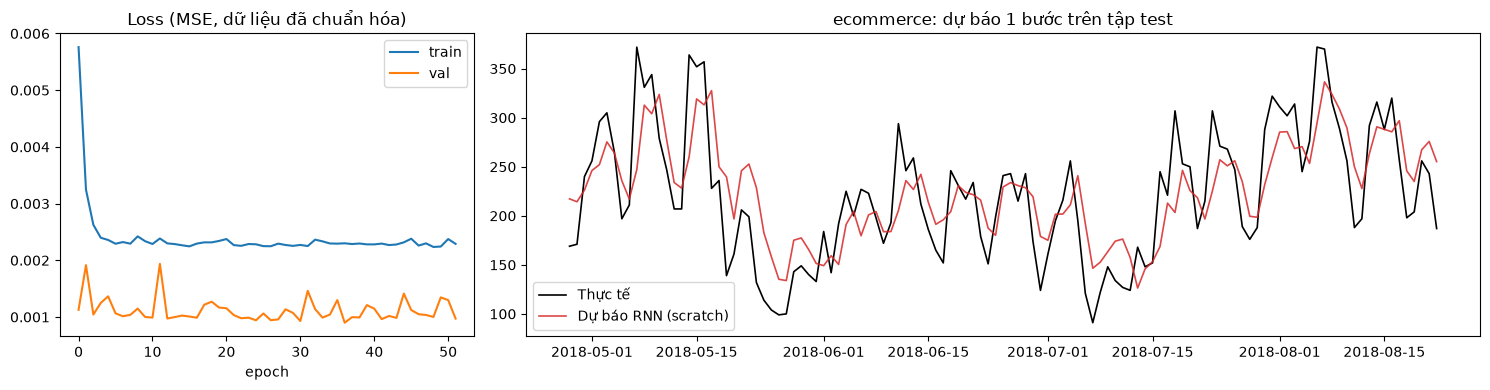

In [7]:
d = DATASETS['ecommerce']
t0 = time.time()
model, hist = train_scratch(d)
train_time = time.time() - t0
print(f'Số tham số: {model.n_params()} | thời gian huấn luyện: {train_time:.1f} s')

y_pred = d['to_original'](model.predict(d['X_test']))
y_true = d['y_test_orig']
m_rnn = regression_metrics(y_true, y_pred)
m_naive = regression_metrics(y_true, d['naive_test'])
display(pd.DataFrame({'RNN scratch': m_rnn, 'Naive (x_t-1)': m_naive}).T.round(3))
plot_results('ecommerce', hist, y_true, y_pred, 'scratch')
res_ecommerce = save_results('scratch', 'ecommerce', m_rnn, m_naive, train_time, len(hist['train']), {'n_params': model.n_params()})

## 5. Dataset: Stock — NASDAQ (IXIC)

epoch   1 | train 0.98167 | val 1.56722 | ||g|| 2.695


epoch  10 | train 0.91320 | val 1.57728 | ||g|| 2.400


epoch  20 | train 0.76586 | val 1.61968 | ||g|| 3.675


Early stopping tại epoch 22, best val = 1.49000
Số tham số: 4289 | thời gian huấn luyện: 4.4 s


,RMSE,MAE,MAPE,R2
RNN scratch,158.298,107.273,1.098,0.995
Naive (x_t-1),158.243,107.550,1.103,0.995


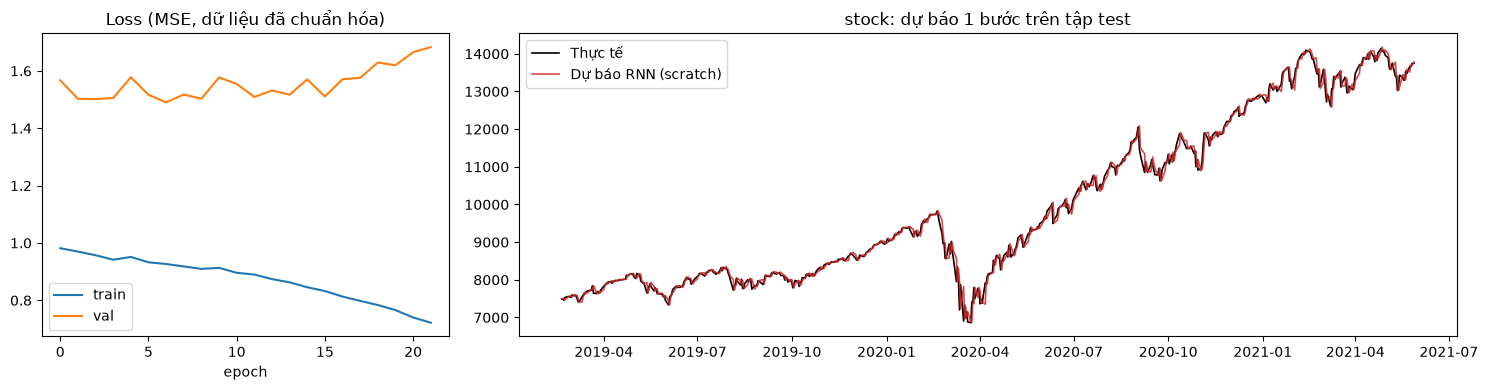

In [8]:
d = DATASETS['stock']
t0 = time.time()
model, hist = train_scratch(d)
train_time = time.time() - t0
print(f'Số tham số: {model.n_params()} | thời gian huấn luyện: {train_time:.1f} s')

y_pred = d['to_original'](model.predict(d['X_test']))
y_true = d['y_test_orig']
m_rnn = regression_metrics(y_true, y_pred)
m_naive = regression_metrics(y_true, d['naive_test'])
display(pd.DataFrame({'RNN scratch': m_rnn, 'Naive (x_t-1)': m_naive}).T.round(3))
plot_results('stock', hist, y_true, y_pred, 'scratch')
res_stock = save_results('scratch', 'stock', m_rnn, m_naive, train_time, len(hist['train']), {'n_params': model.n_params()})

## 6. Theo dõi chuẩn gradient trong quá trình huấn luyện
Chuẩn gradient trung bình mỗi epoch (trước khi clip) — minh họa vai trò của gradient clipping.

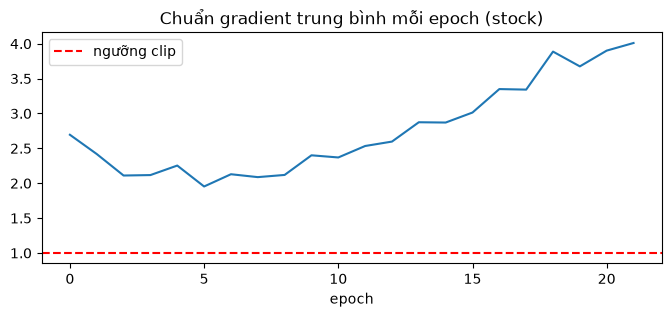

In [9]:
plt.figure(figsize=(8, 3)); plt.plot(hist['grad_norm']); plt.axhline(CLIP, color='r', ls='--', label='ngưỡng clip')
plt.title('Chuẩn gradient trung bình mỗi epoch (stock)'); plt.xlabel('epoch'); plt.legend(); plt.show()

## 7. Tổng kết

In [10]:
pd.DataFrame({k: {**v['metrics'], 'naive_RMSE': v['naive_baseline']['RMSE'], 'epochs': v['epochs'], 'time_s': v['train_time_sec']}
              for k, v in [('ecommerce', res_ecommerce), ('stock', res_stock)]}).T.round(3)

,RMSE,MAE,MAPE,R2,naive_RMSE,epochs,time_s
ecommerce,42.511,34.421,17.487,0.604,49.345,52.0,1.00
stock,158.298,107.273,1.098,0.995,158.243,22.0,4.39


**Nhận xét**
* Gradient check cho sai số tương đối rất nhỏ → BPTT tự cài đặt chính xác.
* **E-commerce:** RNN học được xu hướng và mùa vụ tuần nên cho sai số thấp hơn baseline naive (hôm nay = hôm qua) — dữ liệu dịch vụ có cấu trúc lặp lại mà RNN khai thác được.
* **Stock:** giá cổ phiếu gần như *random walk*, nên baseline naive rất khó vượt qua; RNN chỉ đạt xấp xỉ baseline. Đây là kết quả kỳ vọng, không phải lỗi mô hình.
* Cài đặt từ đầu giúp hiểu rõ: trạng thái ẩn, chia sẻ trọng số, cộng dồn gradient qua thời gian, và vì sao cần clipping/khởi tạo trực giao. Nhược điểm: chậm hơn framework và phải tự viết gradient.